# Практична робота 3

## Перша модель і базове оцінювання якості

**Дисципліна:** Розпізнавання образів та класичне машинне навчання
**Студент:** Святішенко Дмитро
**Група:** ІН-32/2
**Дата виконання:** 28.10.2026

### Мета роботи

Побудувати першу завершену модель машинного навчання, отримати прогнози
та навчитися оцінювати їхню якість за допомогою основних метрик класифікації.

## 1. Підключення бібліотек

In [1]:
from pathlib import Path
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

from IPython.display import display

In [2]:
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

Python: 3.12.11
pandas: 3.0.6
scikit-learn: 1.9.1
joblib: 1.6.0


## 2. Підключення Google Drive

Якщо Notebook запущено поза Colab, Drive не підключається, а робочою папкою вважається корінь репозиторію.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Notebook виконується поза Google Colab — використовується локальна папка проєкту.")

Notebook виконується поза Google Colab — використовується локальна папка проєкту.


In [4]:
if IN_COLAB:
    PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
else:
    # Notebook лежить у папці notebooks/, тому корінь проєкту — на рівень вище
    PROJECT_DIR = Path.cwd().parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "iris_cleaned.csv"
)

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

MODEL_PATH = MODELS_DIR / "iris_decision_tree.joblib"
METRICS_PATH = REPORTS_DIR / "model_metrics.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH.relative_to(PROJECT_DIR))
print("Файл моделі:", MODEL_PATH.relative_to(PROJECT_DIR))

Файл даних: data\processed\iris_cleaned.csv
Файл моделі: models\iris_decision_tree.joblib


## 3. Завантаження підготовленого набору даних

Використовується очищений набір, збережений у практичній роботі 2.

In [5]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл iris_cleaned.csv не знайдено. "
        "Перевірте виконання практичної роботи 2."
    )

data = pd.read_csv(DATA_PATH)

display(data.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


In [6]:
print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)

print("\nКількість пропусків:", data.isna().sum().sum())

Розмір таблиці: (148, 6)

Типи даних:
sepal_length_cm       float64
sepal_width_cm        float64
petal_length_cm       float64
petal_width_cm        float64
species                   str
measurement_device        str
dtype: object

Кількість пропусків: 0


**Відповіді на запитання.**

1. Очищений набір містить **148 об'єктів**.
2. Доступно **5 ознак**: чотири числові вимірювання (`sepal_length_cm`, `sepal_width_cm`, `petal_length_cm`, `petal_width_cm`) і категоріальна `measurement_device`; після one-hot-кодування їх стане 7.
3. Пропущених значень **немає**.
4. Цільова змінна — **`species`** (вид ірису).

## 4. Формування ознак і цільової змінної

Цільова змінна `species` не входить до складу `X`, оскільки це спричинило б витік правильної відповіді.
У цій роботі ціль залишається текстовою — моделі scikit-learn працюють з текстовими назвами класів.

In [7]:
X = data.drop(columns=["species"])
y = data["species"]

categorical_columns = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Категоріальні ознаки:", categorical_columns)

Категоріальні ознаки: ['measurement_device']


In [8]:
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

display(X.head())

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


Розмір X: (148, 7)
Розмір y: (148,)


## 5. Формування навчальної й тестової вибірок

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


In [10]:
split_distribution = pd.DataFrame(
    {
        "train_percent": (
            y_train
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        ),
        "test_percent": (
            y_test
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)

display(split_distribution)

,train_percent,test_percent
species,,
setosa,33.90,33.33
versicolor,33.05,33.33
virginica,33.05,33.33


**Відповіді на запитання.**

1. Тестова вибірка не використовується для навчання, щоб оцінити якість на об'єктах, яких модель не бачила. Інакше оцінка була б завищеною й не показувала б роботу на нових даних.
2. `random_state=42` фіксує випадкове розбиття: при кожному запуску отримуються ті самі train і test, тож результати відтворювані. Розбиття збігається з вибірками, збереженими в практичній роботі 2.
3. `stratify=y` зберігає однакові частки класів у train і test.
4. Так, частки близькі: у train 33,90 / 33,05 / 33,05 % (40 / 39 / 39 об'єктів), у test — рівно по 33,33 % (по 10 об'єктів).

## 6. Базова модель DummyClassifier

DummyClassifier використовується як найпростіший орієнтир. Він не аналізує ознаки
та завжди прогнозує найпоширеніший клас навчальної вибірки.

In [11]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_train_predictions = dummy_model.predict(X_train)
dummy_test_predictions = dummy_model.predict(X_test)

dummy_preview = pd.DataFrame(
    {
        "actual": y_test.iloc[:10].values,
        "predicted": dummy_test_predictions[:10]
    }
)

display(dummy_preview)

,actual,predicted
0,versicolor,setosa
1,versicolor,setosa
2,virginica,setosa
3,setosa,setosa
4,virginica,setosa
5,versicolor,setosa
6,versicolor,setosa
7,setosa,setosa
8,virginica,setosa
9,virginica,setosa


DummyClassifier завжди прогнозує **setosa** — у навчальній вибірці це найчастіший клас
(40 з 118 об'єктів проти 39 у кожного з інших). Така модель недостатня: вона ігнорує вимірювання
квітки і за будь-яких ознак видає одну відповідь, тому правильно класифікує лише об'єкти одного класу.

## 7. Дерево рішень

Будується дерево рішень з обмеженою максимальною глибиною `max_depth=3`, що зменшує ризик перенавчання.

In [12]:
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

tree_train_predictions = tree_model.predict(X_train)
tree_test_predictions = tree_model.predict(X_test)

prediction_preview = pd.DataFrame(
    {
        "actual": y_test.iloc[:15].values,
        "predicted": tree_test_predictions[:15]
    }
)

prediction_preview["correct"] = (
    prediction_preview["actual"]
    == prediction_preview["predicted"]
)

display(prediction_preview)
print("Правильних серед перших 15:", prediction_preview["correct"].sum())

,actual,predicted,correct
0,versicolor,versicolor,True
1,versicolor,versicolor,True
2,virginica,virginica,True
3,setosa,setosa,True
4,virginica,virginica,True
5,versicolor,versicolor,True
6,versicolor,versicolor,True
7,setosa,setosa,True
8,virginica,virginica,True
9,virginica,virginica,True


Правильних серед перших 15: 15


Усі **15 з 15** перших прогнозів дерева правильні.

Структуру навченого дерева наведено нижче.

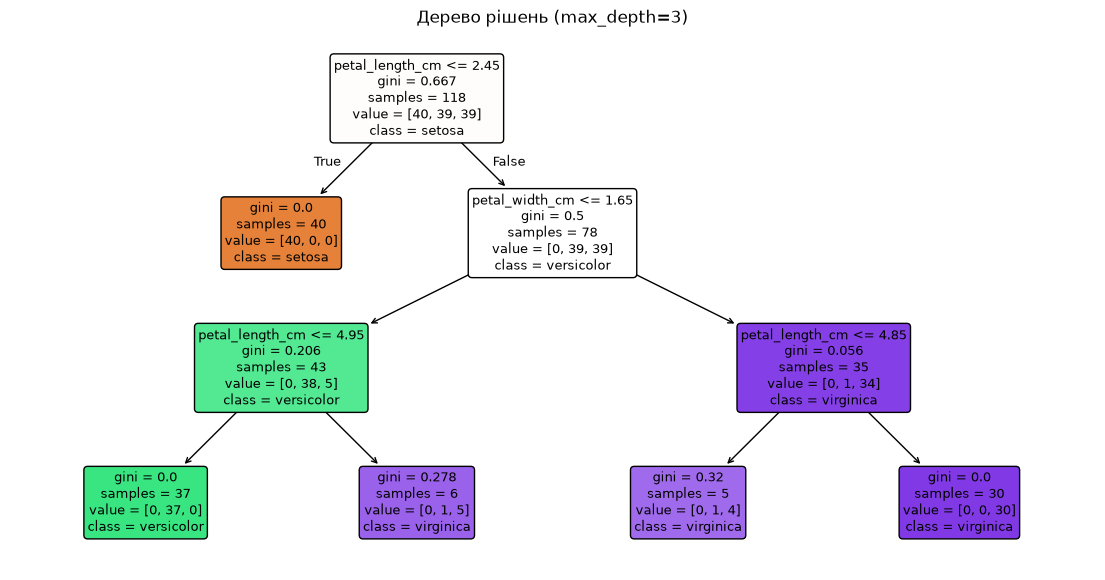

In [13]:
plt.figure(figsize=(14, 7))

plot_tree(
    tree_model,
    feature_names=X.columns.tolist(),
    class_names=tree_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Дерево рішень (max_depth=3)")
plt.savefig(FIGURES_DIR / "pr03_tree.png", dpi=150, bbox_inches="tight")
plt.show()

Дерево використовує лише ознаки пелюстки: перше розбиття `petal_length_cm <= 2,45` повністю
відокремлює setosa, далі `petal_width_cm <= 1,65` і `petal_length_cm` розділяють versicolor і virginica.
Ознаки чашолистка й пристрою вимірювання не використано — це узгоджується з EDA практичних робіт 1–2.

## 8. Розрахунок метрик

У багатокласовій задачі використовується `average="macro"`: метрика обчислюється для кожного класу
окремо, після чого знаходиться середнє — кожен клас має однакову вагу. Параметр `zero_division=0`
потрібен для DummyClassifier, який ніколи не прогнозує два класи.

In [14]:
def calculate_metrics(
    model_name,
    dataset_name,
    y_true,
    y_pred
):
    """
    Обчислює основні метрики багатокласової класифікації.
    """
    return {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

In [15]:
metrics_rows = [
    calculate_metrics("DummyClassifier", "train", y_train, dummy_train_predictions),
    calculate_metrics("DummyClassifier", "test", y_test, dummy_test_predictions),
    calculate_metrics("DecisionTree", "train", y_train, tree_train_predictions),
    calculate_metrics("DecisionTree", "test", y_test, tree_test_predictions)
]

metrics_df = pd.DataFrame(metrics_rows)

display(metrics_df.round(3))

,model,dataset,accuracy,precision_macro,recall_macro,f1_macro
0,DummyClassifier,train,0.339,0.113,0.333,0.169
1,DummyClassifier,test,0.333,0.111,0.333,0.167
2,DecisionTree,train,0.983,0.984,0.983,0.983
3,DecisionTree,test,0.933,0.936,0.933,0.933


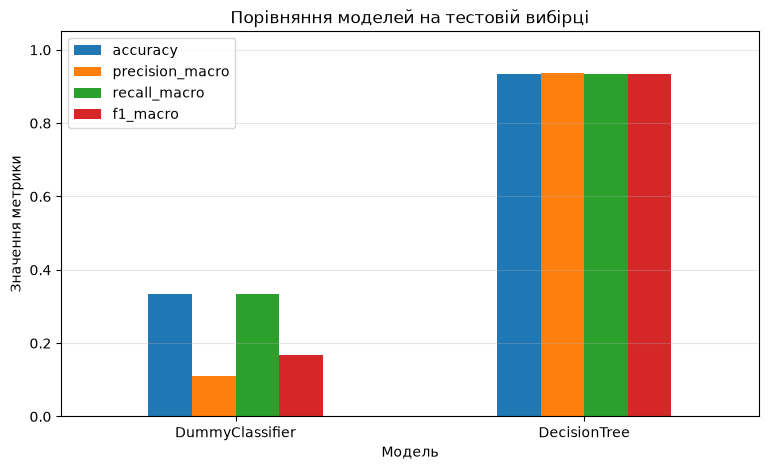

In [16]:
test_metrics = (
    metrics_df[metrics_df["dataset"] == "test"]
    .set_index("model")
)

test_metrics[
    [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Порівняння моделей на тестовій вибірці")
plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper left")
plt.savefig(FIGURES_DIR / "pr03_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Відповіді на запитання.**

1. Вищу accuracy має **дерево рішень**: 0,933 проти 0,333 у DummyClassifier.
2. Вищу F1-міру також має **дерево рішень**: 0,933 проти 0,167.
3. Дерево перевищує DummyClassifier на 0,600 за accuracy (60 відсоткових пунктів, 28 правильних відповідей проти 10) і на 0,767 за F1-macro.
4. Accuracy недостатньо, бо вона не показує, які саме класи модель плутає. Наприклад, DummyClassifier має accuracy 0,333, хоча взагалі не розпізнає два з трьох класів — це видно лише з precision-macro 0,111 і F1-macro 0,167. На незбалансованих даних «завжди найчастіший клас» може мати навіть високу accuracy.

## 9. Порівняння train і test

In [17]:
train_test_comparison = metrics_df.pivot(
    index="model",
    columns="dataset",
    values=[
        "accuracy",
        "f1_macro"
    ]
)

display(train_test_comparison.round(3))

accuracy        f1_macro       
dataset             test  train     test  train
model                                          
DecisionTree       0.933  0.983    0.933  0.983
DummyClassifier    0.333  0.339    0.167  0.169

In [18]:
tree_train_accuracy = accuracy_score(y_train, tree_train_predictions)
tree_test_accuracy = accuracy_score(y_test, tree_test_predictions)

accuracy_gap = tree_train_accuracy - tree_test_accuracy

print("Accuracy на train:", round(tree_train_accuracy, 3))
print("Accuracy на test:", round(tree_test_accuracy, 3))
print("Різниця:", round(accuracy_gap, 3))

Accuracy на train: 0.983
Accuracy на test: 0.933
Різниця: 0.05


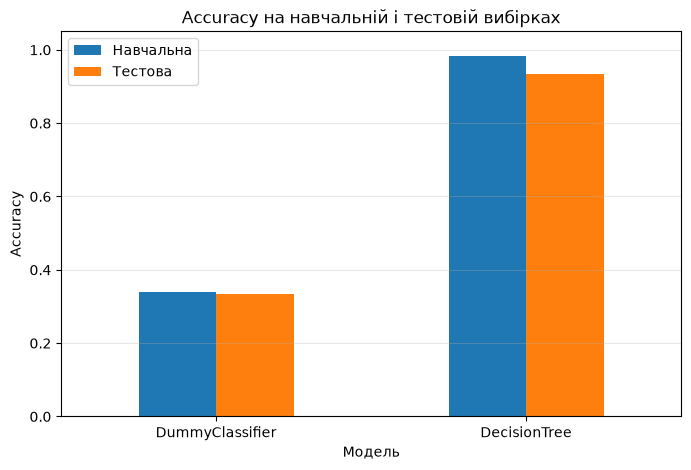

In [19]:
accuracy_comparison = pd.DataFrame(
    {
        "train": [
            accuracy_score(y_train, dummy_train_predictions),
            tree_train_accuracy
        ],
        "test": [
            accuracy_score(y_test, dummy_test_predictions),
            tree_test_accuracy
        ]
    },
    index=["DummyClassifier", "DecisionTree"]
)

accuracy_comparison.plot(kind="bar", figsize=(8, 5))

plt.title("Accuracy на навчальній і тестовій вибірках")
plt.xlabel("Модель")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(["Навчальна", "Тестова"], loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.savefig(FIGURES_DIR / "pr03_train_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Відповіді на запитання.**

1. Так, DummyClassifier **недонавчений**: низька якість і на train (0,339), і на test (0,333) при майже нульовому розриві — модель надто проста, щоб виявити закономірності.
2. Вираженого **перенавчання дерева немає**: train 0,983, test 0,933, розрив 0,050. На train дерево помиляється у 2 об'єктах із 118 (обидва — versicolor у зоні перекриття), на test — у 2 із 30.
3. Так, дерево має **прийнятну узагальнювальну здатність**: висока якість на test, суттєва перевага над базовою моделлю й невеликий розрив. Тест містить лише 30 об'єктів, тож одна помилка змінює accuracy на 3,3 відсоткового пункту.

## 10. Матриця помилок

Матриця помилок показує, які класи модель визначає правильно, а які плутає між собою.
Рядки відповідають справжнім класам, стовпці — прогнозам.

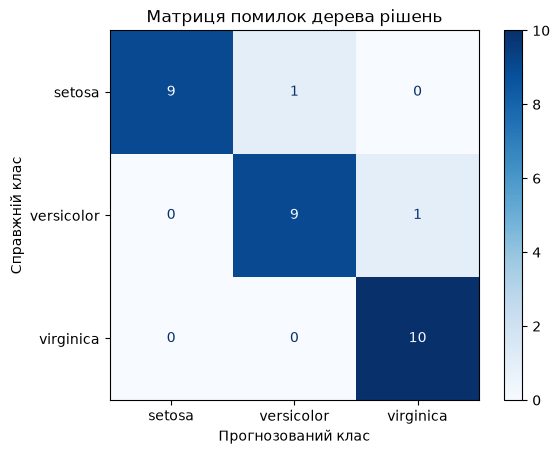

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tree_test_predictions,
    cmap="Blues"
)

plt.title("Матриця помилок дерева рішень")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")
plt.savefig(FIGURES_DIR / "pr03_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Відповіді на запитання.**

1. Правильно класифіковано **28 з 30** об'єктів (сума діагоналі: 9 + 9 + 10).
2. Без помилок розпізнано **virginica** — усі 10 об'єктів (recall = 1,0). Setosa і versicolor мають по одній помилці.
3. Однієї найчастішої пари немає: по одній помилці setosa → versicolor та versicolor → virginica.
4. Помилка versicolor → virginica узгоджується з діаграмами попередніх робіт, де ці види перекриваються. Помилка для setosa — несподівана, бо setosa відокремлюється найкраще; її причину розглянуто нижче.

## 11. Аналіз помилкових прогнозів

In [21]:
test_results = X_test.copy()

test_results["actual"] = y_test.values
test_results["predicted"] = tree_test_predictions

test_results["correct"] = (
    test_results["actual"]
    == test_results["predicted"]
)

mistakes = test_results[~test_results["correct"]]

display(mistakes)
print("Кількість помилкових прогнозів:", len(mistakes))

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c,actual,predicted,correct
10,5.4,3.7,4.3,0.2,1,0,0,setosa,versicolor,False
77,6.7,3.0,5.0,1.7,0,1,0,versicolor,virginica,False


Кількість помилкових прогнозів: 2


**Аналіз помилок.**

- **Об'єкт 10: setosa → versicolor.** Пелюстка має довжину 4,3 см і ширину 0,2 см — для setosa довжина зазвичай до 1,9 см. Саме в цьому рядку в практичній роботі 2 довжину пелюстки було штучно замінено на −1,0; аномалію замінено пропуском і заповнено загальною медіаною 4,3 см. Дерево перевіряє спочатку довжину пелюстки (поріг 2,45 см) і тому віднесло квітку до versicolor. Причина помилки — не модель, а втрата справжнього значення під час заповнення пропусків.
- **Об'єкт 77: versicolor → virginica.** Пелюстка 5,0 × 1,7 см лежить точно в зоні перекриття versicolor і virginica (довжина 4,5–5,1 см, ширина 1,4–1,8 см) і перевищує пороги дерева `petal_width_cm > 1,65`, `petal_length_cm > 4,85`. Це природна складність даних.

Модель не виправлялася з урахуванням цих тестових об'єктів — це підлаштувало б її під test.

## 12. Збереження навченої моделі

Модель зберігається разом із назвами ознак, щоб її можна було правильно використати в наступних роботах.

In [22]:
model_bundle = {
    "model": tree_model,
    "feature_columns": X.columns.tolist(),
    "target_classes": sorted(y.unique().tolist())
}

joblib.dump(model_bundle, MODEL_PATH)

print("Модель збережено:", MODEL_PATH.relative_to(PROJECT_DIR))

Модель збережено: models\iris_decision_tree.joblib


### 12.1. Перевірка завантаження

In [23]:
loaded_bundle = joblib.load(MODEL_PATH)
loaded_model = loaded_bundle["model"]

print("Ознаки моделі:", loaded_bundle["feature_columns"])
print("Класи:", loaded_bundle["target_classes"])

one_object = X_test.iloc[[0]]
loaded_prediction = loaded_model.predict(one_object)

print("Справжній клас:", y_test.iloc[0])
print("Прогноз моделі:", loaded_prediction[0])

print(
    "Прогнози завантаженої моделі збігаються з початковою:",
    (loaded_model.predict(X_test) == tree_test_predictions).all()
)

Ознаки моделі: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'measurement_device_device_a', 'measurement_device_device_b', 'measurement_device_device_c']
Класи: ['setosa', 'versicolor', 'virginica']
Справжній клас: versicolor
Прогноз моделі: versicolor
Прогнози завантаженої моделі збігаються з початковою: True


### 12.2. Збереження таблиці метрик

In [24]:
metrics_df.to_csv(METRICS_PATH, index=False)

print("Таблицю метрик збережено:", METRICS_PATH.relative_to(PROJECT_DIR))

Таблицю метрик збережено: reports\model_metrics.csv


## 13. Автоматична перевірка

In [25]:
assert X_train.isna().sum().sum() == 0, (
    "У X_train залишилися пропуски."
)

assert X_test.isna().sum().sum() == 0, (
    "У X_test залишилися пропуски."
)

assert len(tree_test_predictions) == len(y_test), (
    "Кількість прогнозів не відповідає кількості тестових об’єктів."
)

assert set(tree_test_predictions).issubset(
    set(y_train.unique())
), "Модель прогнозує невідомий клас."

assert MODEL_PATH.exists(), (
    "Файл моделі не збережено."
)

assert tree_test_accuracy > accuracy_score(
    y_test,
    dummy_test_predictions
), (
    "Дерево не перевищує базову модель. "
    "Перевірте підготовку даних."
)

print("Усі основні перевірки виконано успішно.")

Усі основні перевірки виконано успішно.


## 14. Додаткове завдання: дерево без обмеження глибини

In [26]:
deep_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

deep_tree.fit(X_train, y_train)

deep_train_predictions = deep_tree.predict(X_train)
deep_test_predictions = deep_tree.predict(X_test)

print("Train accuracy:", accuracy_score(y_train, deep_train_predictions))
print("Test accuracy:", accuracy_score(y_test, deep_test_predictions))

Train accuracy: 1.0
Test accuracy: 0.9


In [27]:
depth_comparison = pd.DataFrame(
    [
        {
            "model": "max_depth=3",
            "depth": tree_model.get_depth(),
            "leaves": tree_model.get_n_leaves(),
            "train_accuracy": tree_train_accuracy,
            "test_accuracy": tree_test_accuracy
        },
        {
            "model": "max_depth=None",
            "depth": deep_tree.get_depth(),
            "leaves": deep_tree.get_n_leaves(),
            "train_accuracy": accuracy_score(y_train, deep_train_predictions),
            "test_accuracy": accuracy_score(y_test, deep_test_predictions)
        }
    ]
)

depth_comparison["gap"] = (
    depth_comparison["train_accuracy"]
    - depth_comparison["test_accuracy"]
)

display(depth_comparison.round(3))

,model,depth,leaves,train_accuracy,test_accuracy,gap
0,max_depth=3,3,5,0.983,0.933,0.05
1,max_depth=None,5,9,1.000,0.900,0.10


**Відповіді на запитання.**

1. Так, необмежене дерево (глибина 5, 9 листків) досягло accuracy **1,0** на train — воно запам'ятало всі навчальні об'єкти.
2. Ні, якість на test **погіршилася**: 0,900 (27 з 30) проти 0,933 у дерева глибини 3.
3. Так, розрив зріс з 0,050 до **0,100**.
4. Так, це ознака **перенавчання**: модель підлаштувалася під окремі навчальні точки в зоні перекриття versicolor/virginica і гірше працює з новими об'єктами. Обмеження глибини діє як регуляризація.

# Висновки

Під час виконання практичної роботи було побудовано перші моделі машинного навчання
для класифікації об'єктів набору Iris.

Як базовий орієнтир використано DummyClassifier, який завжди прогнозував найпоширеніший клас.
Його результати показали рівень якості, який повинна перевищувати реальна модель.

Як основну модель побудовано дерево рішень із максимальною глибиною 3. Модель було навчено
на навчальній вибірці, після чого отримано прогнози для навчальних і тестових даних.

Якість моделей оцінено за accuracy, precision, recall і F1-мірою. Дерево рішень показало кращі
результати порівняно з базовою моделлю, що підтверджує наявність закономірностей між ознаками
квітки та її видом.

За допомогою матриці помилок було визначено, які класи модель розпізнає правильно та які класи
вона може плутати. Порівняння результатів на навчальній і тестовій вибірках дало змогу оцінити
узагальнювальну здатність моделі.

Навчену модель і перелік використаних ознак збережено у форматі joblib для подальшого використання.

**Конкретні результати:**

- accuracy DummyClassifier на test — **0,333** (F1-macro 0,167): модель завжди прогнозує setosa;
- accuracy дерева на train — **0,983**, на test — **0,933**;
- F1-macro дерева на test — **0,933** (precision-macro 0,936, recall-macro 0,933);
- різниця між train і test — **0,050**;
- кількість помилкових прогнозів на test — **2 з 30**;
- модель по одному разу сплутала setosa → versicolor (наслідок заповнення пошкодженої довжини пелюстки медіаною 4,3 см) і versicolor → virginica (зона перекриття видів); усі virginica розпізнано правильно;
- DummyClassifier недонавчений; дерево глибини 3 не має ознак перенавчання і добре узагальнює, тоді як необмежене дерево (train 1,000, test 0,900) перенавчається.

Отримана оцінка має навчальне обмеження: параметри очищення в практичній роботі 2 обчислювалися
на всьому наборі до розбиття. У наступних роботах перетворення будуть навчатися лише на train
у складі Pipeline.